# Segmentasi dan Ekstraksi Fitur Citra Sel Darah Merah untuk Membedakan Sel Terinfeksi dan Tidak Terinfeksi

## 1. Pendahuluan dan Tujuan

**Dataset:** Malaria Cell Images (Kaggle), dua kelas: `Parasitized` (terinfeksi) dan `Uninfected` (tidak terinfeksi).

**Tujuan:**
1. Melakukan preprocessing citra sel darah (resize, grayscale, noise removal, contrast enhancement, normalisasi).
2. Melakukan segmentasi klasik (Otsu, k-means, HSV, morfologi, Canny).
3. Mengekstraksi fitur warna, tekstur, dan bentuk.
4. Mengklasifikasikan sel dengan SVM, Random Forest, dan KNN, lalu mengevaluasinya.

**Alur:** Citra -> Preprocessing -> Segmentasi -> Ekstraksi fitur -> Klasifikasi -> Evaluasi

## 2. Setup Colab dan Download Dataset

In [ ]:
!pip -q install kagglehub

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Pengaturan
SEED = 42
JUMLAH_PER_KELAS = 1000   # jumlah citra yang dipakai per kelas (biar ringan di Colab)
UKURAN = 128              # ukuran citra setelah resize
KELAS = ["Uninfected", "Parasitized"]   # label 0 = Uninfected, 1 = Parasitized

random.seed(SEED)
np.random.seed(SEED)

In [ ]:
import kagglehub

root = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")
print("Lokasi dataset:", root)

# Cari folder yang berisi Parasitized dan Uninfected
for folder, subfolder, files in os.walk(root):
    if "Parasitized" in subfolder and "Uninfected" in subfolder:
        DATA_DIR = folder
        break

print("DATA_DIR:", DATA_DIR)
print(os.listdir(DATA_DIR))

100%|██████████| 675M/675M [00:26<00:00, 26.4MB/s]

Extracting files...


Lokasi dataset: /root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1
DATA_DIR: /root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images
['Parasitized', 'cell_images', 'Uninfected']


## 3. Eksplorasi Data
Menampilkan jumlah citra per kelas, contoh citra, dan ukuran citra.

Uninfected     13779
Parasitized    13779
dtype: int64


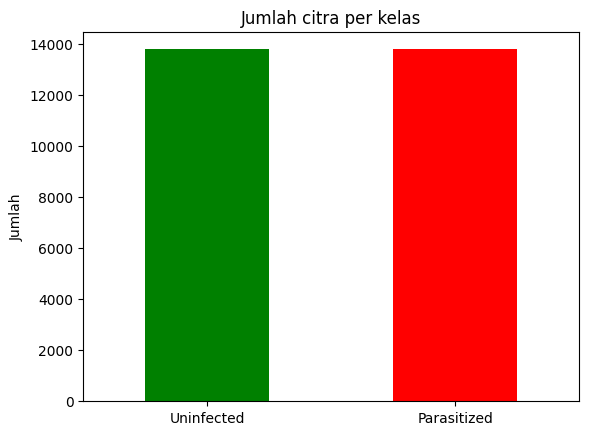

In [ ]:
# Jumlah citra per kelas
semua_path = {}
for k in KELAS:
    semua_path[k] = glob.glob(os.path.join(DATA_DIR, k, "*.png"))

jumlah = pd.Series({k: len(p) for k, p in semua_path.items()})
print(jumlah)

jumlah.plot(kind="bar", color=["green", "red"], rot=0)
plt.title("Jumlah citra per kelas")
plt.ylabel("Jumlah")
plt.show()

In [ ]:
# Ambil sebagian citra secara acak (jumlahnya sama untuk tiap kelas)
data_list = []
for label, k in enumerate(KELAS):
    terpilih = random.sample(semua_path[k], min(JUMLAH_PER_KELAS, len(semua_path[k])))
    for p in terpilih:
        data_list.append([p, k, label])

df = pd.DataFrame(data_list, columns=["path", "kelas", "label"])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(df["kelas"].value_counts())
df.head()

kelas
Parasitized    1000
Uninfected     1000
Name: count, dtype: int64


,path,kelas,label
0,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1
1,/root/.cache/kagglehub/datasets/iarunava/cell-...,Uninfected,0
2,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1
3,/root/.cache/kagglehub/datasets/iarunava/cell-...,Uninfected,0
4,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1


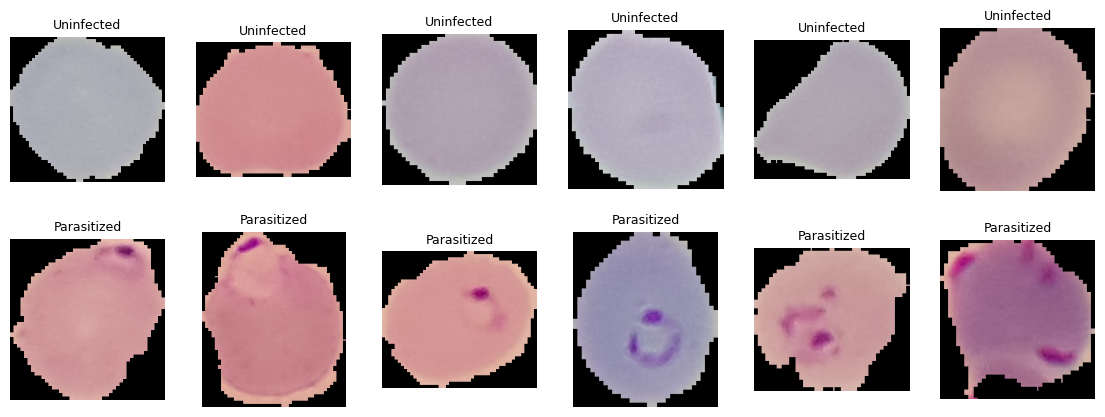

In [ ]:
def baca_rgb(path):
    img = cv2.imread(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Contoh citra tiap kelas
plt.figure(figsize=(14, 5))
nomor = 1
for k in KELAS:
    contoh = df[df["kelas"] == k]["path"].head(6)
    for p in contoh:
        plt.subplot(2, 6, nomor)
        plt.imshow(baca_rgb(p))
        plt.title(k, fontsize=9)
        plt.axis("off")
        nomor += 1
plt.show()

Lebar  : min 82 | max 259 | rata-rata 133.3
Tinggi : min 76 | max 217 | rata-rata 132.8


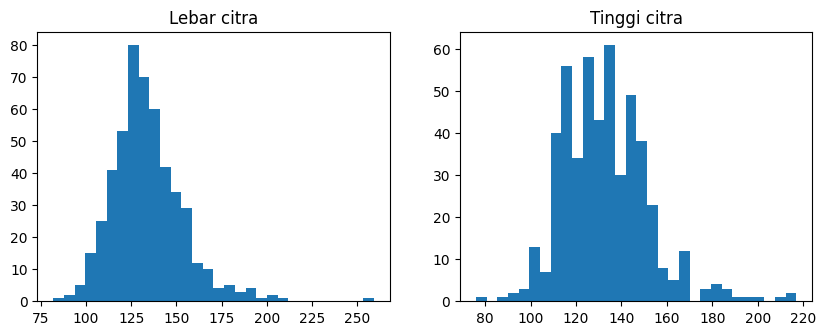

Ukuran citra tidak seragam, jadi perlu di-resize.


In [ ]:
# Ukuran citra
lebar, tinggi = [], []
for p in df["path"].head(500):
    w, h = Image.open(p).size
    lebar.append(w)
    tinggi.append(h)

print("Lebar  : min", min(lebar), "| max", max(lebar), "| rata-rata", round(np.mean(lebar), 1))
print("Tinggi : min", min(tinggi), "| max", max(tinggi), "| rata-rata", round(np.mean(tinggi), 1))

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.hist(lebar, bins=30)
plt.title("Lebar citra")
plt.subplot(1, 2, 2)
plt.hist(tinggi, bins=30)
plt.title("Tinggi citra")
plt.show()
print("Ukuran citra tidak seragam, jadi perlu di-resize.")

## 4. Preprocessing
Menampilkan perbandingan sebelum dan sesudah: resize, Gaussian blur, median blur, CLAHE, dan grayscale.

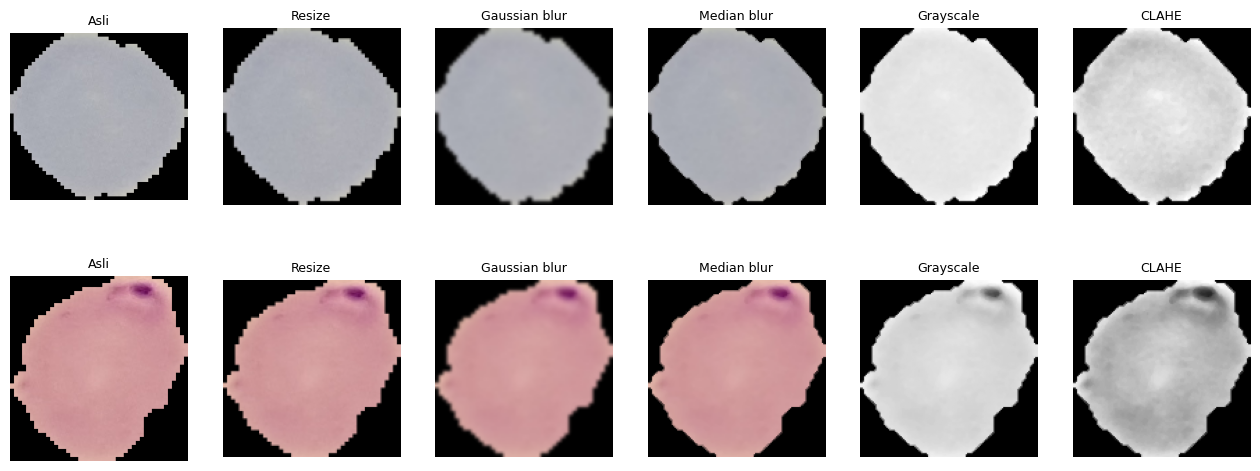

In [ ]:
# Ambil satu contoh dari tiap kelas
contoh_path = [df[df["kelas"] == "Uninfected"]["path"].iloc[0],
               df[df["kelas"] == "Parasitized"]["path"].iloc[0]]

plt.figure(figsize=(16, 6))
for i, p in enumerate(contoh_path):
    asli = baca_rgb(p)
    resize = cv2.resize(asli, (UKURAN, UKURAN))
    gaussian = cv2.GaussianBlur(resize, (5, 5), 0)
    median = cv2.medianBlur(resize, 3)
    gray = cv2.cvtColor(median, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(gray)

    gambar = [asli, resize, gaussian, median, gray, clahe]
    judul = ["Asli", "Resize", "Gaussian blur", "Median blur", "Grayscale", "CLAHE"]
    for j in range(6):
        plt.subplot(2, 6, i * 6 + j + 1)
        if j >= 4:
            plt.imshow(gambar[j], cmap="gray")
        else:
            plt.imshow(gambar[j])
        plt.title(judul[j], fontsize=9)
        plt.axis("off")
plt.show()

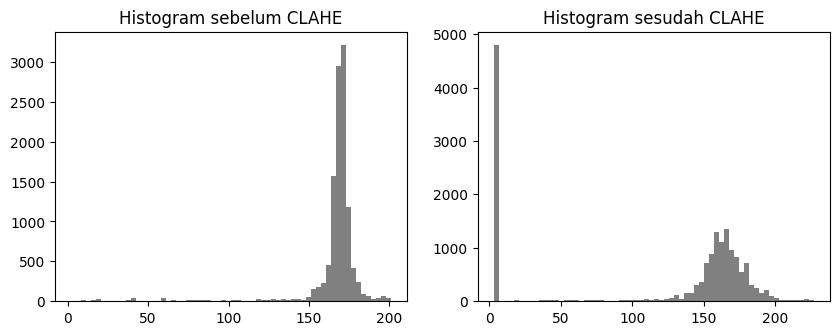

Nilai min: 0.0 | nilai max: 0.9333333333333333


In [ ]:
# Histogram sebelum dan sesudah CLAHE (piksel latar hitam tidak dihitung)
p = contoh_path[1]
gray = cv2.cvtColor(cv2.medianBlur(cv2.resize(baca_rgb(p), (UKURAN, UKURAN)), 3), cv2.COLOR_RGB2GRAY)
gray_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(gray)

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.hist(gray[gray > 0].ravel(), bins=64, color="gray")
plt.title("Histogram sebelum CLAHE")
plt.subplot(1, 2, 2)
plt.hist(gray_clahe[gray_clahe > 0].ravel(), bins=64, color="gray")
plt.title("Histogram sesudah CLAHE")
plt.show()

# Normalisasi (nilai piksel dijadikan 0 - 1)
normalisasi = cv2.resize(baca_rgb(p), (UKURAN, UKURAN)) / 255.0
print("Nilai min:", normalisasi.min(), "| nilai max:", normalisasi.max())

## 5. Segmentasi
Ada dua tahap:
1. **Segmentasi sel:** memisahkan sel dari latar hitam (threshold + morfologi).
2. **Segmentasi parasit:** mencari bagian ungu gelap di dalam sel. Beberapa metode dibandingkan: Otsu pada kanal hijau, k-means, dan threshold warna HSV (metode final), ditambah Canny sebagai pembanding.

**Catatan:** parasit dicari dengan dua syarat: warnanya ungu (hue HSV) **dan** lebih gelap daripada sitoplasma sel itu sendiri (dibandingkan dengan median kanal hijau di dalam sel). Nilai `HUE_BAWAH`, `HUE_ATAS`, dan `SELISIH_GELAP` adalah nilai awal. Lihat hasilnya, lalu ubah jika mask parasit terlalu banyak atau terlalu sedikit.

In [ ]:
from sklearn.cluster import KMeans

# Pengaturan segmentasi parasit. Silakan diubah jika perlu.
HUE_BAWAH = 110       # batas hue ungu-biru (skala OpenCV 0 - 179)
HUE_ATAS = 165
SELISIH_GELAP = 25    # parasit harus lebih gelap dari median kanal hijau sel, minimal sebesar ini

def segmentasi_sel(img):
    # Segmentasi sel: threshold sederhana, karena latarnya hitam
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 1, cv2.THRESH_BINARY)
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    # Ambil kontur terbesar, lalu isi penuh (supaya tidak ada lubang)
    kontur, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    sel = np.zeros_like(mask)
    if len(kontur) > 0:
        terbesar = max(kontur, key=cv2.contourArea)
        cv2.drawContours(sel, [terbesar], -1, 1, -1)
    return sel

def mask_mentah(img, sel):
    # Piksel parasit = berwarna ungu DAN lebih gelap dari sitoplasma sel
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hijau = img[:, :, 1].astype(int)
    median_hijau = np.median(hijau[sel == 1])
    gelap = hijau < (median_hijau - SELISIH_GELAP)
    ungu = (hsv[:, :, 0] >= HUE_BAWAH) & (hsv[:, :, 0] <= HUE_ATAS)
    return (gelap & ungu & (sel == 1)).astype(np.uint8)

def segmentasi_parasit(img, sel):
    # Metode final: mask mentah, lalu dirapikan dengan morfologi
    mask = mask_mentah(img, sel)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)    # hapus bintik kecil
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)   # tutup lubang kecil
    return mask

def otsu_hijau(img, sel):
    hijau = img[:, :, 1]
    t, _ = cv2.threshold(hijau[sel == 1], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ((hijau < t) & (sel == 1)).astype(np.uint8)

def kmeans_parasit(img, sel):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    piksel = lab[sel == 1].astype(np.float32)
    hasil = np.zeros(sel.shape, np.uint8)
    if len(piksel) < 3:
        return hasil
    km = KMeans(n_clusters=3, n_init=3, random_state=SEED).fit(piksel)
    tergelap = np.argmin(km.cluster_centers_[:, 0])   # klaster dengan kecerahan terendah
    hasil[sel == 1] = (km.labels_ == tergelap).astype(np.uint8)
    return hasil

def gambar_kontur(img, mask):
    hasil = img.copy()
    kontur, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(hasil, kontur, -1, (255, 255, 0), 1)
    return hasil

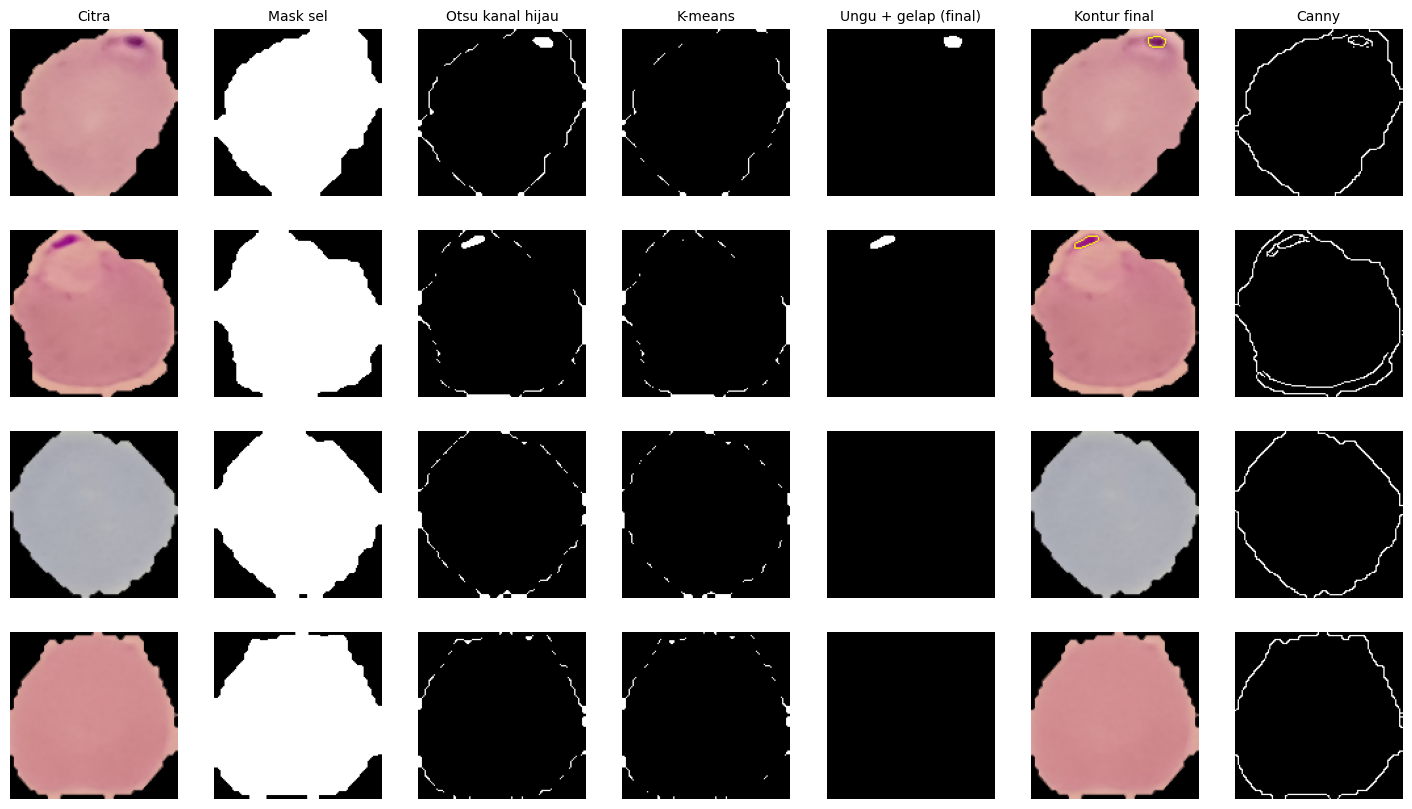

In [ ]:
# Bandingkan metode segmentasi pada 2 sel Parasitized dan 2 sel Uninfected
contoh = (list(df[df["kelas"] == "Parasitized"]["path"].head(2)) +
          list(df[df["kelas"] == "Uninfected"]["path"].head(2)))

judul = ["Citra", "Mask sel", "Otsu kanal hijau", "K-means", "Ungu + gelap (final)", "Kontur final", "Canny"]
plt.figure(figsize=(18, 10))
for i, p in enumerate(contoh):
    img = cv2.medianBlur(cv2.resize(baca_rgb(p), (UKURAN, UKURAN)), 3)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    sel = segmentasi_sel(img)
    final = segmentasi_parasit(img, sel)
    canny = cv2.Canny(gray, 40, 120)

    hasil = [img, sel, otsu_hijau(img, sel), kmeans_parasit(img, sel), final,
             gambar_kontur(img, final), canny]
    for j in range(7):
        plt.subplot(4, 7, i * 7 + j + 1)
        if hasil[j].ndim == 2:
            plt.imshow(hasil[j], cmap="gray")
        else:
            plt.imshow(hasil[j])
        if i == 0:
            plt.title(judul[j], fontsize=10)
        plt.axis("off")
plt.show()

Piksel parasit sebelum morfologi: 118 | sesudah: 115


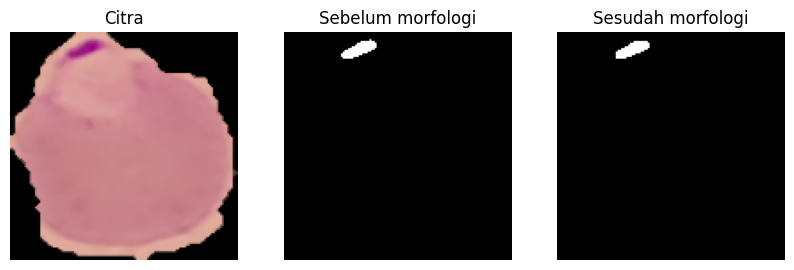

In [ ]:
# Pengaruh operasi morfologi pada mask parasit
p = df[df["kelas"] == "Parasitized"]["path"].iloc[1]
img = cv2.medianBlur(cv2.resize(baca_rgb(p), (UKURAN, UKURAN)), 3)
sel = segmentasi_sel(img)

mentah = mask_mentah(img, sel)
bersih = segmentasi_parasit(img, sel)
print("Piksel parasit sebelum morfologi:", mentah.sum(), "| sesudah:", bersih.sum())

plt.figure(figsize=(10, 3.5))
for i, (g, t) in enumerate(zip([img, mentah, bersih], ["Citra", "Sebelum morfologi", "Sesudah morfologi"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(g, cmap="gray" if g.ndim == 2 else None)
    plt.title(t)
    plt.axis("off")
plt.show()

**Bahan pembahasan:** metode mana yang paling bersih? Apakah sel Uninfected kadang ikut terdeteksi memiliki "parasit" (false positive)? Watershed tidak dipakai karena satu citra hanya berisi satu sel.

## 6. Ekstraksi Fitur
- **Warna:** rata-rata dan standar deviasi RGB dan HSV pada area sel.
- **Tekstur:** GLCM (contrast, homogeneity, energy, correlation).
- **Bentuk:** luas, keliling, circularity sel, serta luas, jumlah, dan rasio area parasit terhadap sel.

In [ ]:
from skimage.feature import graycomatrix, graycoprops

def ekstrak_fitur(path):
    img = cv2.medianBlur(cv2.resize(baca_rgb(path), (UKURAN, UKURAN)), 3)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    sel = segmentasi_sel(img)
    parasit = segmentasi_parasit(img, sel)
    luas_sel = int(sel.sum())
    if luas_sel < 200:        # sel tidak terdeteksi, citra dilewati
        return None

    fitur = {}

    # --- Fitur warna (hanya piksel di dalam sel) ---
    for i, nama in enumerate(["R", "G", "B"]):
        nilai = img[:, :, i][sel == 1]
        fitur["mean_" + nama] = nilai.mean()
        fitur["std_" + nama] = nilai.std()
    for i, nama in enumerate(["H", "S", "V"]):
        nilai = hsv[:, :, i][sel == 1]
        fitur["mean_" + nama] = nilai.mean()
        fitur["std_" + nama] = nilai.std()

    # --- Fitur tekstur (GLCM) ---
    g = gray.copy()
    g[sel == 0] = 0                       # latar dijadikan 0
    g = (g // 8).astype(np.uint8)         # 32 tingkat keabuan
    glcm = graycomatrix(g, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=False).astype(np.float64)
    glcm[0, :, :, :] = 0                  # abaikan pasangan piksel yang melibatkan latar
    glcm[:, 0, :, :] = 0
    glcm = glcm / np.maximum(glcm.sum(axis=(0, 1), keepdims=True), 1)
    for prop in ["contrast", "homogeneity", "energy", "correlation"]:
        fitur["glcm_" + prop] = graycoprops(glcm, prop).mean()

    # --- Fitur bentuk ---
    kontur, _ = cv2.findContours(sel, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(kontur, key=cv2.contourArea)
    luas = cv2.contourArea(c)
    keliling = cv2.arcLength(c, True)
    fitur["sel_luas"] = luas
    fitur["sel_keliling"] = keliling
    fitur["sel_circularity"] = 4 * np.pi * luas / (keliling ** 2) if keliling > 0 else 0

    jumlah, _, stats, _ = cv2.connectedComponentsWithStats(parasit)
    luas_parasit = stats[1:, cv2.CC_STAT_AREA].sum() if jumlah > 1 else 0
    fitur["parasit_luas"] = luas_parasit
    fitur["parasit_jumlah"] = jumlah - 1
    fitur["parasit_rasio"] = luas_parasit / luas_sel
    return fitur

In [ ]:
# Ekstraksi fitur untuk semua citra (butuh beberapa menit)
hasil_fitur = []
indeks_ok = []
for i in range(len(df)):
    try:
        f = ekstrak_fitur(df["path"][i])
    except Exception:
        f = None
    if f is not None:
        hasil_fitur.append(f)
        indeks_ok.append(i)
    if (i + 1) % 500 == 0:
        print("Diproses:", i + 1, "dari", len(df))

data = pd.concat([df.loc[indeks_ok].reset_index(drop=True), pd.DataFrame(hasil_fitur)], axis=1)
data = data.replace([np.inf, -np.inf], np.nan).dropna()
print("Citra berhasil diproses:", len(data), "dari", len(df))
data.to_csv("fitur_malaria.csv", index=False)   # disimpan supaya tidak perlu diulang
data.head()

Diproses: 500 dari 2000
Diproses: 1000 dari 2000
Diproses: 1500 dari 2000
Diproses: 2000 dari 2000
Citra berhasil diproses: 2000 dari 2000


,path,kelas,label,mean_R,std_R,mean_G,std_G,mean_B,std_B,mean_H,...,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,sel_luas,sel_keliling,sel_circularity,parasit_luas,parasit_jumlah,parasit_rasio
0,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1,203.760333,28.341705,147.558391,22.793855,151.273782,21.052225,138.183724,...,3.869456,0.907014,0.551391,0.597341,11446.5,433.261972,0.766269,107,1,0.009195
1,/root/.cache/kagglehub/datasets/iarunava/cell-...,Uninfected,0,168.610664,24.762157,169.954572,24.920477,177.112532,26.079221,111.314841,...,3.509521,0.928713,0.668618,0.467222,11852.5,433.404108,0.792928,0,0,0.000000
2,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1,200.365687,31.377244,133.431561,24.959178,138.806449,21.993531,135.332221,...,3.247198,0.887021,0.463838,0.648453,12080.5,445.806128,0.763841,115,1,0.009364
3,/root/.cache/kagglehub/datasets/iarunava/cell-...,Uninfected,0,205.786754,26.536140,139.947939,18.455507,141.985602,18.375234,141.717566,...,2.983421,0.940376,0.671478,0.466120,12988.5,456.492422,0.783252,0,0,0.000000
4,/root/.cache/kagglehub/datasets/iarunava/cell-...,Parasitized,1,209.045555,26.887116,149.200343,23.338186,147.498081,19.097052,15.571475,...,4.603773,0.904659,0.598953,0.583621,12056.0,436.190905,0.796269,104,1,0.008490


Jumlah fitur: 22
kelas             Parasitized  Uninfected
parasit_rasio           0.023       0.001
parasit_luas          267.467      11.085
mean_G                142.263     152.771
mean_S                 64.668      50.636
glcm_contrast           3.312       3.157
glcm_homogeneity        0.899       0.924
sel_circularity         0.719       0.767
sel_luas            11672.970   11936.954


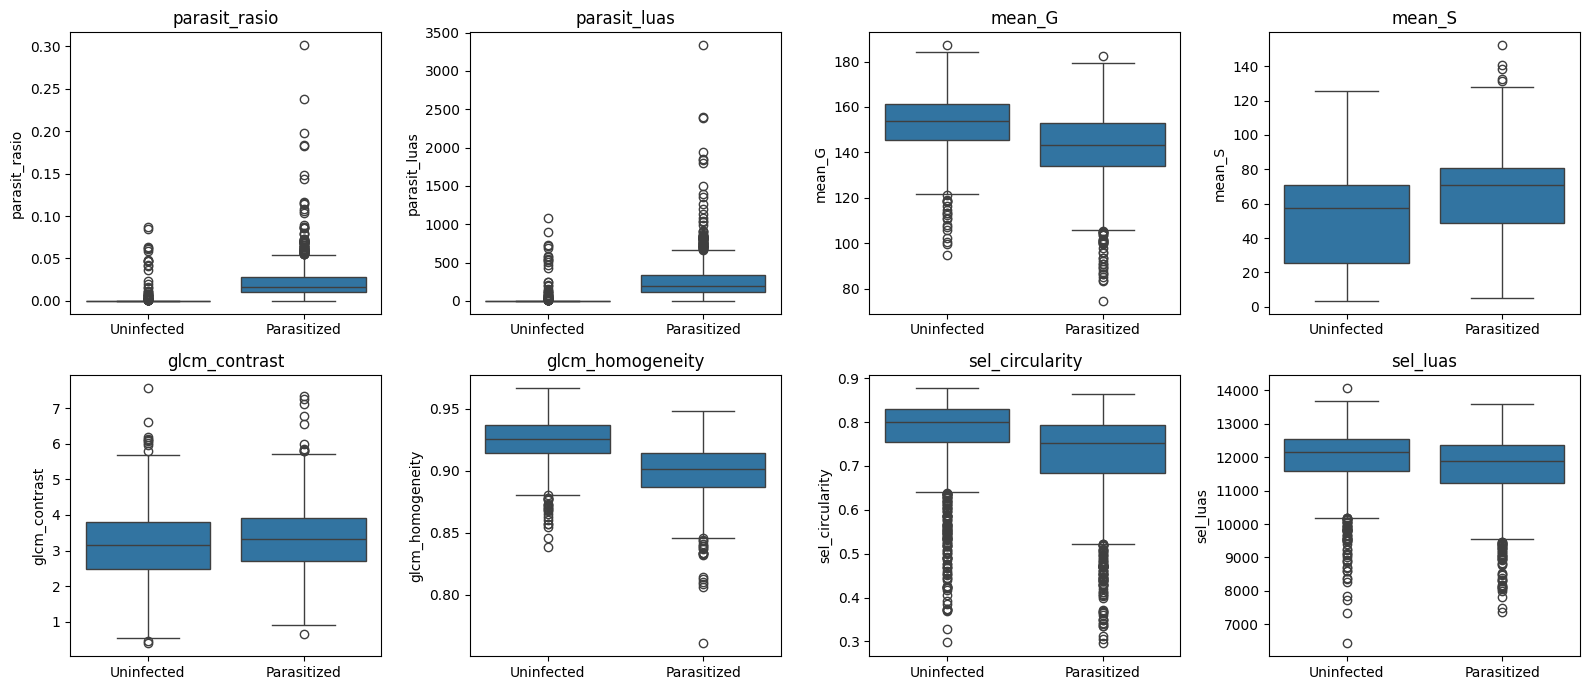

In [ ]:
FITUR = [c for c in data.columns if c not in ["path", "kelas", "label"]]
print("Jumlah fitur:", len(FITUR))

# Rata-rata fitur utama per kelas
fitur_utama = ["parasit_rasio", "parasit_luas", "mean_G", "mean_S", "glcm_contrast", "glcm_homogeneity", "sel_circularity", "sel_luas"]
print(data.groupby("kelas")[fitur_utama].mean().round(3).T)

# Boxplot fitur utama per kelas
plt.figure(figsize=(16, 7))
for i, ft in enumerate(fitur_utama):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(data=data, x="kelas", y=ft, order=KELAS)
    plt.title(ft)
    plt.xlabel("")
plt.tight_layout()
plt.show()

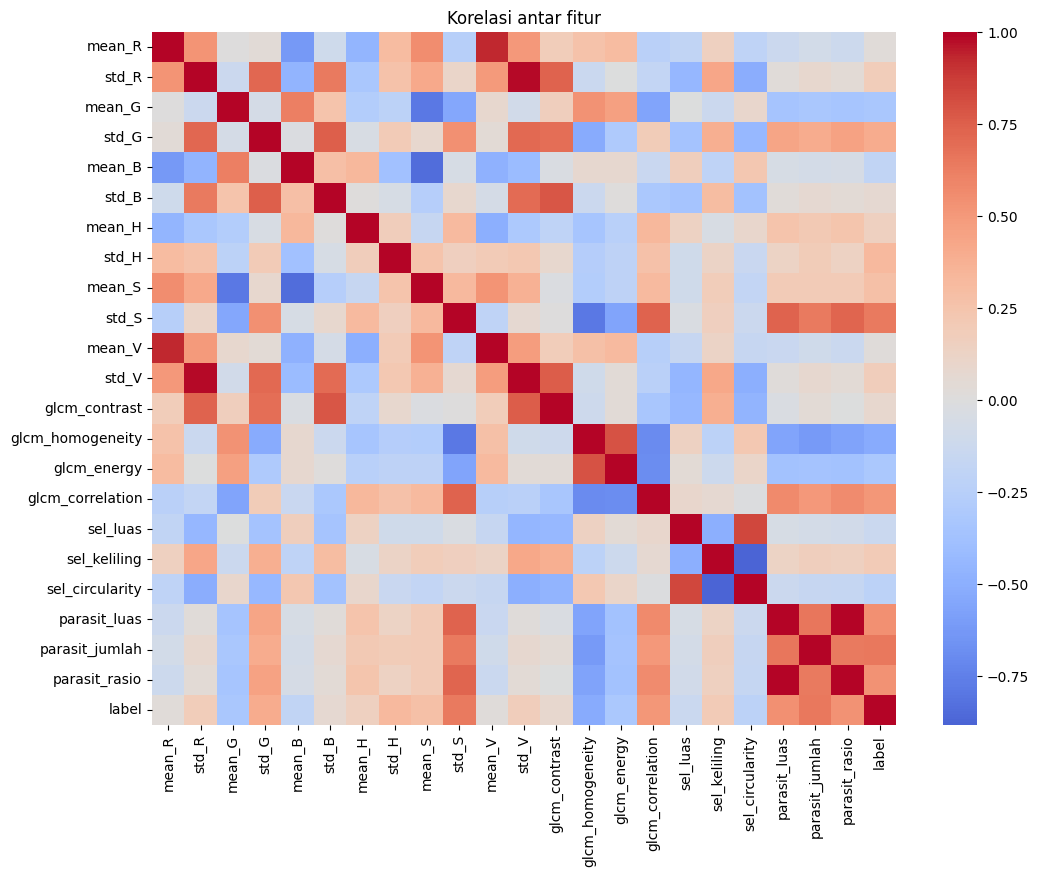

In [ ]:
# Heatmap korelasi antar fitur
plt.figure(figsize=(12, 9))
sns.heatmap(data[FITUR + ["label"]].corr(), cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur")
plt.show()

## 7. Pelatihan Model ML
Model yang dipakai: SVM, Random Forest, dan KNN. Data dibagi 80% latih dan 20% uji. Fitur diskalakan dengan `StandardScaler` (hanya di-fit pada data latih).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = data[FITUR]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

# Normalisasi fitur
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Data latih: (1600, 22) | Data uji: (400, 22)


In [ ]:
model = {
    "SVM": SVC(kernel="rbf", C=1, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

akurasi = {}
prediksi = {}
for nama, m in model.items():
    m.fit(X_train_s, y_train)
    prediksi[nama] = m.predict(X_test_s)
    akurasi[nama] = accuracy_score(y_test, prediksi[nama])
    print(nama, "-> akurasi:", round(akurasi[nama], 4))

SVM -> akurasi: 0.965
Random Forest -> akurasi: 0.9625
KNN -> akurasi: 0.9375


## 8. Evaluasi
Menampilkan perbandingan akurasi, confusion matrix, classification report, contoh salah prediksi, dan fitur terpenting.

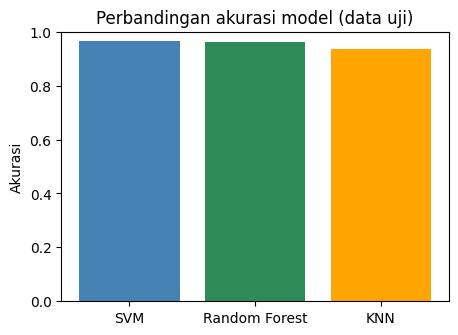

Model terbaik: SVM


In [ ]:
# Perbandingan akurasi
plt.figure(figsize=(5, 3.5))
plt.bar(akurasi.keys(), akurasi.values(), color=["steelblue", "seagreen", "orange"])
plt.ylim(0, 1)
plt.ylabel("Akurasi")
plt.title("Perbandingan akurasi model (data uji)")
plt.show()

terbaik = max(akurasi, key=akurasi.get)
print("Model terbaik:", terbaik)

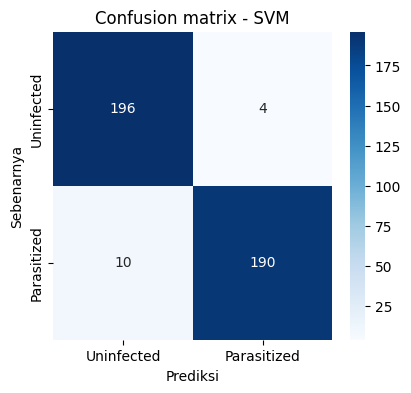

              precision    recall  f1-score   support

  Uninfected       0.95      0.98      0.97       200
 Parasitized       0.98      0.95      0.96       200

    accuracy                           0.96       400
   macro avg       0.97      0.96      0.96       400
weighted avg       0.97      0.96      0.96       400



In [ ]:
# Confusion matrix dan classification report model terbaik
y_pred = prediksi[terbaik]

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=KELAS, yticklabels=KELAS)
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.title("Confusion matrix - " + terbaik)
plt.show()

print(classification_report(y_test, y_pred, target_names=KELAS))

Jumlah salah prediksi: 14


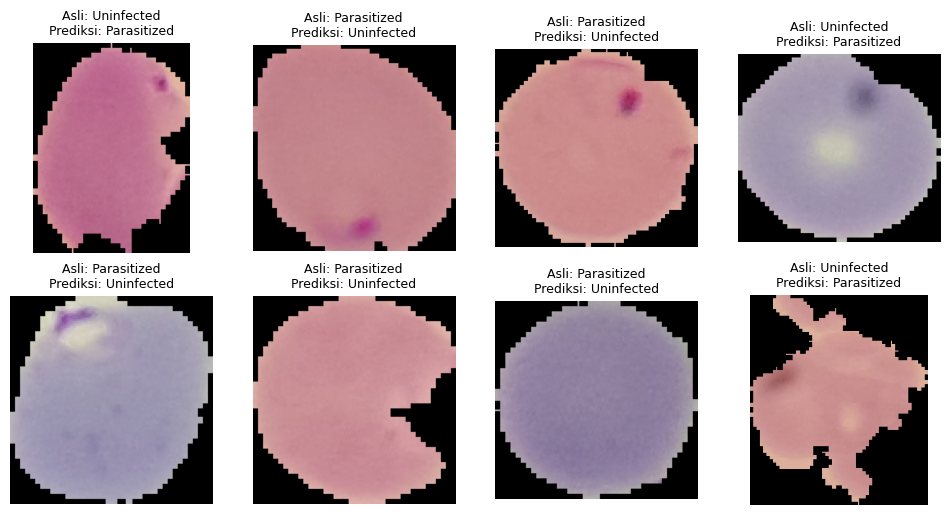

In [ ]:
# Contoh citra yang salah diprediksi
salah = np.where(y_test.values != y_pred)[0]
print("Jumlah salah prediksi:", len(salah))

plt.figure(figsize=(12, 6))
for i, s in enumerate(salah[:8]):
    baris = data.loc[y_test.index[s]]
    plt.subplot(2, 4, i + 1)
    plt.imshow(baca_rgb(baris["path"]))
    plt.title("Asli: " + KELAS[y_test.values[s]] + "\nPrediksi: " + KELAS[y_pred[s]], fontsize=9)
    plt.axis("off")
plt.show()

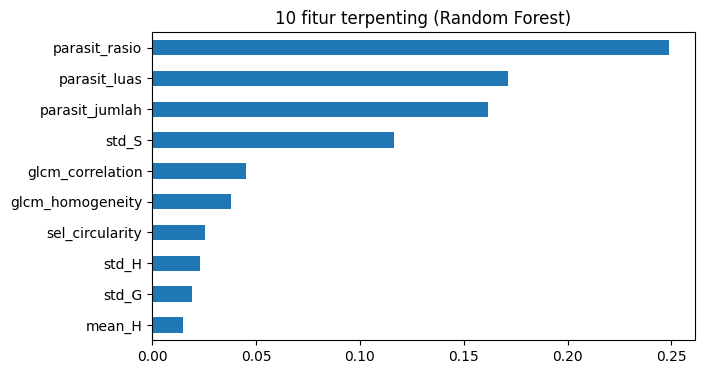

In [ ]:
# Fitur terpenting menurut Random Forest
rf = model["Random Forest"]
penting = pd.Series(rf.feature_importances_, index=FITUR).sort_values(ascending=False).head(10)
penting[::-1].plot(kind="barh", figsize=(7, 4))
plt.title("10 fitur terpenting (Random Forest)")
plt.show()

## 9. Kesimpulan dan Kendala

**Kesimpulan (isi dengan hasilmu):**
1. Preprocessing: apa pengaruh median blur dan CLAHE pada citra?
2. Segmentasi: metode mana yang paling baik memisahkan parasit? Metode mana yang sering gagal?
3. Fitur: fitur apa yang paling membedakan sel Parasitized dan Uninfected?
4. Model: model terbaik dan akurasinya. Kelas mana yang sering tertukar?

**Kendala (tulis yang benar-benar dialami):**
- Ukuran citra tidak seragam, diatasi dengan resize.
- Pengaturan hue dan selisih gelap sensitif terhadap perbedaan pewarnaan antar citra.
- Sel Uninfected yang punya noda kadang ikut terdeteksi sebagai parasit.
- Hanya memakai sebagian dataset (`JUMLAH_PER_KELAS`) agar ringan di Colab.
- Tidak ada mask ground-truth, jadi kualitas segmentasi dinilai secara visual.